In [52]:
import pandas as pd 
df=pd.read_csv("h.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [54]:
df.shape


(891, 12)

In [55]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [56]:
df["Survived"].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [57]:
df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [58]:
df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [59]:
df.shape


(891, 12)

In [60]:
df["Embarked"]=df["Embarked"].fillna(df["Embarked"].mode()[0])


In [61]:
df["Embarked"].isnull().sum()


np.int64(0)

In [62]:
df["Age"]=df["Age"].fillna(df["Age"].median())


In [63]:
df['Age'].isnull().sum()

np.int64(0)

In [64]:
df[["Age", "Fare"]].describe()

,Age,Fare
count,891.000000,891.000000
mean,29.361582,32.204208
std,13.019697,49.693429
min,0.420000,0.000000
25%,22.000000,7.910400
50%,28.000000,14.454200
75%,35.000000,31.000000
max,80.000000,512.329200


In [65]:
df.duplicated().sum()

np.int64(0)

In [66]:
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')
counts = df['Title'].value_counts()
df['Title'] = df['Title'].replace(counts[counts < 10].index, 'Rare')

# 2. Age groups
df['AgeGroup'] = pd.cut(df['Age'], bins=[0, 12, 18, 60, 100],
                        labels=['Child', 'Teen', 'Adult', 'Senior'])

# 3. Ticket group size
df['TicketGroupSize'] = df['Ticket'].map(df['Ticket'].value_counts())

# 4. Fare per person
df['FarePerPerson'] = df['Fare'] / df['TicketGroupSize']

# 5. Fare bins
df['FareBin'] = pd.qcut(df['Fare'], 4, labels=['Low', 'Mid', 'High', 'VeryHigh'])

print(df.groupby('Title')['Survived'].mean())
print(df.groupby('AgeGroup')['Survived'].mean())
print(df.groupby('TicketGroupSize')['Survived'].mean())
print(df.groupby('FareBin')['Survived'].mean())# 1. Title from Name


Title
Master    0.575000
Miss      0.702703
Mr        0.156673
Mrs       0.793651
Rare      0.347826
Name: Survived, dtype: float64
AgeGroup
Child     0.579710
Teen      0.428571
Adult     0.365753
Senior    0.227273
Name: Survived, dtype: float64
TicketGroupSize
1    0.297989
2    0.574468
3    0.698413
4    0.500000
5    0.000000
6    0.000000
7    0.238095
Name: Survived, dtype: float64
FareBin
Low         0.197309
Mid         0.303571
High        0.454955
VeryHigh    0.581081
Name: Survived, dtype: float64


C:\Users\Mohan\AppData\Local\Temp\ipykernel_30484\2059596709.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('AgeGroup')['Survived'].mean())
C:\Users\Mohan\AppData\Local\Temp\ipykernel_30484\2059596709.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('FareBin')['Survived'].mean())# 1. Title from Name


In [67]:

print(df.nunique())

PassengerId        891
Survived             2
Pclass               3
Name               891
Sex                  2
Age                 88
SibSp                7
Parch                7
Ticket             681
Fare               248
Cabin              147
Embarked             3
Title                5
AgeGroup             4
TicketGroupSize      7
FarePerPerson      248
FareBin              4
dtype: int64


In [68]:
df=df.drop(["Name","PassengerId","Ticket","Cabin","Fare","Title", "SibSp","Parch"], axis=1)

In [69]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder(categories=[["Child", "Teen", "Adult", "Senior"],
                                     ["Low", "Mid", "High", "VeryHigh"]])
col=["AgeGroup" ,"FareBin"]
df[col] = encoder.fit_transform(df[col])
print(encoder.categories_)
cols=["Sex","Embarked"]
df=pd.get_dummies(df,columns=cols, drop_first=True)

[array(['Child', 'Teen', 'Adult', 'Senior'], dtype=object), array(['Low', 'Mid', 'High', 'VeryHigh'], dtype=object)]


In [70]:
from sklearn.model_selection import train_test_split
X = df.drop("Survived", axis=1)
Y=df["Survived"]
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2, random_state=42,stratify=Y)

In [71]:
from sklearn.linear_model import LogisticRegression
l = LogisticRegression()
l.fit(X_train, Y_train)
from sklearn.ensemble import RandomForestClassifier
r = RandomForestClassifier(max_depth=5, random_state=42)
r.fit(X_train, Y_train)



C:\Users\Mohan\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,n_estimators,100
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [72]:
from sklearn.ensemble import GradientBoostingClassifier
g = GradientBoostingClassifier(random_state=42)
g.fit(X_train, Y_train)


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [73]:
from sklearn.model_selection import cross_val_score,StratifiedKFold,KFold,ShuffleSplit,cross_validate 

k=KFold(n_splits=5, shuffle=True, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores_l = cross_val_score(l, X_train, Y_train, cv=cv)
cv_scores_r = cross_val_score(r, X_train, Y_train, cv=cv)
cv_scores_kl=cross_val_score(l, X_train, Y_train, cv=k)
cv_scores_kr=cross_val_score(r, X_train, Y_train, cv=k)
ss = ShuffleSplit(n_splits=5, test_size=0.2, random_state=42)
cv_scores_ls = cross_val_score(l, X_train, Y_train, cv=ss)
cv_scores_rs = cross_val_score(r, X_train, Y_train, cv=ss)
ll=cross_validate(l, X_train, Y_train, cv=cv, return_train_score=True)
rr=cross_validate(r, X_train, Y_train, cv=cv, return_train_score=True,scoring=['accuracy','roc_auc','f1',])
gg=cross_validate(g, X_train, Y_train, cv=cv, return_train_score=True,scoring=['accuracy','roc_auc','f1'])


C:\Users\Mohan\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\Mohan\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/mod

In [74]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,roc_auc_score,f1_score,roc_curve
l_pred = l.predict(X_test)
r_pred = r.predict(X_test)
print("Cross-Validation Scores - Logistic Regression:")
print(cv_scores_l)
print("Cross-Validation Scores - Random Forest:")
print(cv_scores_r)
print("Cross-Validation Scores - Logistic Regression (KFold):")
print(cv_scores_kl)
print("Cross-Validation Scores - Random Forest (KFold):")
print(cv_scores_kr)
print("Cross-Validation Scores - Logistic Regression (ShuffleSplit):", cv_scores_ls.mean(), cv_scores_ls.std())
print("Cross-Validation Scores - Random Forest (ShuffleSplit):", cv_scores_rs.mean(), cv_scores_rs.std())
print("\nLogistic Regression Accuracy:", accuracy_score(Y_test, l_pred))
print("Random Forest Accuracy:", accuracy_score(Y_test, r_pred))

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(Y_test, l_pred))

print("\nRandom Forest Confusion Matrix:")
print(confusion_matrix(Y_test, r_pred))

print("\nLogistic Regression Classification Report:")
print(classification_report(Y_test, l_pred))

print("\nRandom Forest Classification Report:")
print(classification_report(Y_test, r_pred))


Cross-Validation Scores - Logistic Regression:
[0.81118881 0.8041958  0.79577465 0.76056338 0.79577465]
Cross-Validation Scores - Random Forest:
[0.82517483 0.81118881 0.86619718 0.78169014 0.80985915]
Cross-Validation Scores - Logistic Regression (KFold):
[0.7972028  0.74825175 0.81690141 0.82394366 0.88028169]
Cross-Validation Scores - Random Forest (KFold):
[0.79020979 0.7972028  0.82394366 0.83802817 0.85211268]
Cross-Validation Scores - Logistic Regression (ShuffleSplit): 0.7972027972027973 0.012509471202796002
Cross-Validation Scores - Random Forest (ShuffleSplit): 0.813986013986014 0.0210255893403817

Logistic Regression Accuracy: 0.7932960893854749
Random Forest Accuracy: 0.8044692737430168

Logistic Regression Confusion Matrix:
[[94 16]
 [21 48]]

Random Forest Confusion Matrix:
[[103   7]
 [ 28  41]]

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.85      0.84       110
           1       0.75  

In [75]:
print(cv_scores_l.mean(), cv_scores_l.std())
print(cv_scores_r.mean(), cv_scores_r.std())
print(cv_scores_kl.mean(), cv_scores_kl.std()  )
print(cv_scores_kr.mean(), cv_scores_kr.std()  )

0.7934994582881907 0.017449717657843682
0.8188220230473752 0.027575857153711445
0.8133162612035851 0.0426689539791828
0.8202994188909681 0.023573341331291693


In [76]:
print(ll['train_score'].mean(), ll['test_score'].mean())
print(rr['train_accuracy'].mean(), rr['test_accuracy'].mean())


0.807934511146055 0.7934994582881907
0.8774612277618475 0.8188220230473752


In [77]:
from sklearn.model_selection import GridSearchCV
grid_params = {
    'n_estimators': [50, 100, 200],'max_depth': [3, 5, 7]
}
GridSearch = GridSearchCV(estimator=r, param_grid=grid_params, cv=cv,scoring='accuracy',return_train_score=True)
GridSearch.fit(X_train, Y_train)
print("Best Parameters:", GridSearch.best_params_)
print("Best Cross-Validation Score:", GridSearch.best_score_)

Best Parameters: {'max_depth': 7, 'n_estimators': 50}
Best Cross-Validation Score: 0.8328966807840047


In [78]:
dataframe=pd.DataFrame(GridSearch.cv_results_)
dataframe["score"]=dataframe['mean_train_score'] - dataframe['mean_test_score']
print(dataframe[['mean_train_score', 'mean_test_score',  'param_max_depth','param_n_estimators','score',]].sort_values(by='score', ascending=False))


   mean_train_score  mean_test_score  param_max_depth  param_n_estimators  \
7          0.916434         0.830080                7                 100   
8          0.916785         0.831488                7                 200   
6          0.912921         0.832897                7                  50   
5          0.875706         0.816025                5                 200   
4          0.877461         0.818822                5                 100   
3          0.878512         0.825845                5                  50   
1          0.845855         0.814587                3                 100   
0          0.840943         0.811799                3                  50   
2          0.845507         0.823038                3                 200   

      score  
7  0.086355  
8  0.085297  
6  0.080025  
5  0.059681  
4  0.058639  
3  0.052667  
1  0.031268  
0  0.029144  
2  0.022469  


In [79]:
print(dataframe[['std_train_score', 'std_test_score','score',]].sort_values(by='score', ascending=False))

   std_train_score  std_test_score     score
7         0.004207        0.024746  0.086355
8         0.002803        0.019133  0.085297
6         0.001398        0.023452  0.080025
5         0.010282        0.028886  0.059681
4         0.008932        0.027576  0.058639
3         0.004039        0.027561  0.052667
1         0.010578        0.028137  0.031268
0         0.010927        0.026852  0.029144
2         0.004260        0.023697  0.022469


In [80]:
grid_={'n_estimators': [100],'max_depth': [2,3,4], 'learning_rate':[0.1,0.5]}
grid=GridSearchCV(estimator=g, param_grid=grid_, cv=cv,scoring='accuracy',return_train_score=True)
grid.fit(X_train, Y_train)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.1, 0.5], 'max_depth': [2, 3, ...], 'n_estimators': [100]}"
,scoring,'accuracy'
,n_jobs,None
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,loss,'log_loss'


In [81]:
print(gg['train_accuracy'].mean(), gg['train_accuracy'].std())
print(gg['test_accuracy'].mean(), gg['test_accuracy'].std())
print(grid.best_params_)

0.9136262448740482 0.005662528188211363
0.8300994779868021 0.029704973450437554
{'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}


In [82]:
data=pd.DataFrame(grid.cv_results_)
data["score"]=data['mean_train_score'] - data['mean_test_score']
print(data[['mean_train_score', 'mean_test_score',  'param_max_depth','score',"param_learning_rate"]].sort_values(by='score', ascending=False))

   mean_train_score  mean_test_score  param_max_depth     score  \
5          0.982794         0.806166                4  0.176628   
4          0.976475         0.810391                3  0.166084   
2          0.946629         0.835704                4  0.110925   
3          0.935044         0.828671                2  0.106373   
1          0.913626         0.830099                3  0.083527   
0          0.873943         0.817423                2  0.056519   

   param_learning_rate  
5                  0.5  
4                  0.5  
2                  0.1  
3                  0.5  
1                  0.1  
0                  0.1  


In [83]:
print(data[['std_train_score', 'std_test_score','score',]].sort_values(by='score', ascending=False))

   std_train_score  std_test_score     score
5         0.003025        0.015295  0.176628
4         0.003777        0.026337  0.166084
2         0.004528        0.017276  0.110925
3         0.002898        0.017847  0.106373
1         0.005663        0.029705  0.083527
0         0.006302        0.028100  0.056519


In [84]:
print("RandomForestClassifier", rr)
print("GradientBoostingClassifier", gg)

RandomForestClassifier {'fit_time': array([0.51164818, 0.59669828, 0.54756117, 0.62382722, 0.57287431]), 'score_time': array([0.06359053, 0.06818533, 0.07198024, 0.06870794, 0.05661035]), 'test_accuracy': array([0.82517483, 0.81118881, 0.86619718, 0.78169014, 0.80985915]), 'train_accuracy': array([0.88927944, 0.87521968, 0.8754386 , 0.88421053, 0.86315789]), 'test_roc_auc': array([0.88832645, 0.85413223, 0.92319749, 0.88183923, 0.86952862]), 'train_roc_auc': array([0.9340874 , 0.93493688, 0.92143192, 0.9304401 , 0.93032302]), 'test_f1': array([0.76190476, 0.71578947, 0.8       , 0.69306931, 0.70967742]), 'train_f1': array([0.84444444, 0.82025316, 0.81933842, 0.83663366, 0.79473684])}
GradientBoostingClassifier {'fit_time': array([0.35311389, 0.29704213, 0.24294257, 0.25179863, 0.36890125]), 'score_time': array([0.01753283, 0.01401162, 0.0148952 , 0.01256275, 0.01878405]), 'test_accuracy': array([0.83216783, 0.7972028 , 0.88028169, 0.8028169 , 0.83802817]), 'train_accuracy': array([0.91

In [85]:
train, validation, train_y, validation_y = train_test_split(
    X_train, Y_train, test_size=0.2, random_state=42, stratify=Y_train
)


In [86]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import  roc_curve
re = RandomForestClassifier(max_depth=5, random_state=42)
re.fit(train, train_y)
Y_prob = re.predict_proba(validation)[:, 1]
fpr, tpr, thresholds = roc_curve(validation_y, Y_prob)
print("False Positive Rate:", fpr)
print("True Positive Rate:", tpr)
print("Thresholds:", thresholds)

False Positive Rate: [0.         0.         0.         0.01136364 0.01136364 0.01136364
 0.01136364 0.02272727 0.02272727 0.02272727 0.02272727 0.03409091
 0.03409091 0.07954545 0.07954545 0.11363636 0.11363636 0.125
 0.125      0.13636364 0.13636364 0.14772727 0.14772727 0.20454545
 0.20454545 0.22727273 0.22727273 0.32954545 0.32954545 0.42045455
 0.42045455 0.54545455 0.56818182 0.65909091 0.68181818 0.68181818
 0.73863636 0.73863636 0.75       0.75       0.80681818 0.81818182
 0.84090909 0.85227273 0.86363636 0.86363636 0.94318182 0.96590909
 1.        ]
True Positive Rate: [0.         0.01818182 0.10909091 0.10909091 0.41818182 0.45454545
 0.50909091 0.50909091 0.54545455 0.6        0.61818182 0.61818182
 0.67272727 0.67272727 0.70909091 0.70909091 0.72727273 0.72727273
 0.74545455 0.74545455 0.76363636 0.76363636 0.8        0.8
 0.81818182 0.81818182 0.83636364 0.83636364 0.85454545 0.85454545
 0.87272727 0.87272727 0.87272727 0.87272727 0.87272727 0.89090909
 0.89090909 0.909090

In [87]:
Y_train.value_counts(normalize=True)


Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

In [88]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier
dummy = DummyClassifier(strategy='most_frequent', random_state=42)
dummy.fit(X_train, Y_train)
accuracy = dummy.score(X_test, Y_test)
print("Dummy Classifier Accuracy:", accuracy)
l = LogisticRegression(max_iter=1000)
l.fit(X_train, Y_train)
print(l.score(X_test, Y_test))
r=RandomForestClassifier( random_state=42)
r.fit(X_train, Y_train)
print(r.score(X_test, Y_test))
print(dummy.score(X_train, Y_train),l.score(X_train, Y_train),r.score(X_train, Y_train))


Dummy Classifier Accuracy: 0.6145251396648045
0.7932960893854749
0.7932960893854749
0.6165730337078652 0.8033707865168539 0.9803370786516854


In [89]:
from sklearn.metrics import classification_report
print(classification_report(Y_test, l.predict(X_test)))
l=LogisticRegression(class_weight='balanced')
l.fit(X_train,Y_train)
print(classification_report(Y_test, l.predict(X_test)))

              precision    recall  f1-score   support

           0       0.82      0.85      0.83       110
           1       0.74      0.71      0.73        69

    accuracy                           0.79       179
   macro avg       0.78      0.78      0.78       179
weighted avg       0.79      0.79      0.79       179

              precision    recall  f1-score   support

           0       0.86      0.78      0.82       110
           1       0.70      0.80      0.74        69

    accuracy                           0.79       179
   macro avg       0.78      0.79      0.78       179
weighted avg       0.80      0.79      0.79       179



C:\Users\Mohan\AppData\Roaming\Python\Python312\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [90]:
pre=l.predict_proba(X_test)[:, 1]
Y_prob=(pre>=0.5).astype(int)
print(classification_report(Y_test,Y_prob))

              precision    recall  f1-score   support

           0       0.86      0.78      0.82       110
           1       0.70      0.80      0.74        69

    accuracy                           0.79       179
   macro avg       0.78      0.79      0.78       179
weighted avg       0.80      0.79      0.79       179



In [91]:
from sklearn.metrics import average_precision_score,roc_auc_score
print(average_precision_score(Y_test,pre))
print(roc_auc_score(Y_test,pre))

0.7904848831960144
0.8366271409749672


In [92]:
from sklearn.metrics import precision_recall_curve
precision,recall,thresholds=precision_recall_curve(Y_test,pre)


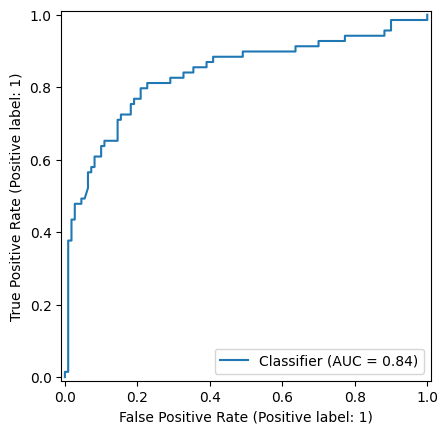

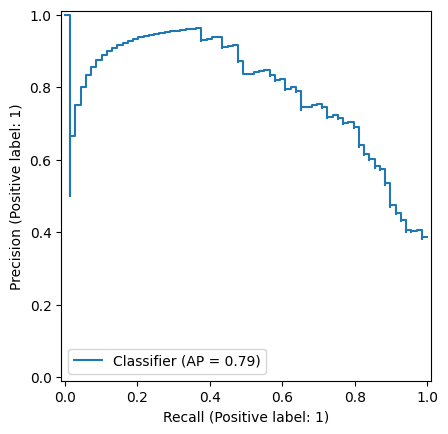

In [93]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay,PrecisionRecallDisplay
RocCurveDisplay.from_predictions(Y_test,pre)
plt.show()
PrecisionRecallDisplay.from_predictions(Y_test,pre)
plt.show()


In [99]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
d=pd.read_csv('h.csv')
X=d.drop(["Survived"],axis=1)

Y=d['Survived']
X=d.drop(["Name","Cabin","Ticket"],axis=1)


In [109]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

n=['Age',"Fare"]
c=[ "Embarked", "Sex", "Pclass"]
npe=Pipeline(steps=[('Simple',SimpleImputer(strategy='median')),('scale', StandardScaler())])
cp=Pipeline(steps=[("cate",OneHotEncoder(handle_unknown="ignore")),('Simple',SimpleImputer(strategy='most_frequent'))])
col=ColumnTransformer([("num",npe,n),("cat",cp,c)])
            
pipeline=Pipeline(steps=[("column",col),('lr',LogisticRegression())])
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,random_state=42,test_size=0.2,stratify=Y)
pipeline.fit(X_train,Y_train)
print(cross_val_score(pipeline,X,Y, cv=5))

pipeline.score(X_test,Y_test)
r=pipeline.predict(X_test)
print(accuracy_score(Y_test,r))

[0.78212291 0.81460674 0.78089888 0.76966292 0.80337079]
0.770949720670391
